In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from ucimlrepo import fetch_ucirepo 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.feature_selection import SelectKBest, chi2

In [ ]:
# fetch dataset 
car_evaluation = fetch_ucirepo(id=19) 
  
# data (as pandas dataframes) 
X = car_evaluation.data.features 
y = car_evaluation.data.targets 
  
# metadata 
print(car_evaluation.metadata) 
  
# variable information 
print(car_evaluation.variables) 


{'uci_id': 19, 'name': 'Car Evaluation', 'repository_url': 'https://archive.ics.uci.edu/dataset/19/car+evaluation', 'data_url': 'https://archive.ics.uci.edu/static/public/19/data.csv', 'abstract': 'Derived from simple hierarchical decision model, this database may be useful for testing constructive induction and structure discovery methods.', 'area': 'Other', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1728, 'num_features': 6, 'feature_types': ['Categorical'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1988, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5JP48', 'creators': ['Marko Bohanec'], 'intro_paper': {'ID': 249, 'type': 'NATIVE', 'title': 'Knowledge acquisition and explanation for multi-attribute decision making', 'authors': 'M. Bohanec, V. Rajkovič', 'venue': '8th Intl Workshop on Expert Systems and their Applications, 

In [3]:
car_evaluation.data.features.describe(include="all")

,buying,maint,doors,persons,lug_boot,safety
count,1728,1728,1728,1728,1728,1728
unique,4,4,4,3,3,3
top,vhigh,vhigh,2,2,small,low
freq,432,432,432,576,576,576


In [4]:
car_evaluation.data.targets.describe(include="all")

,class
count,1728
unique,4
top,unacc
freq,1210


In [5]:
# 1. Logistic Regression
logistic_regression = LogisticRegression(
    max_iter=2000,
    random_state=1
)

# 2. Support Vector Machine
svm = SVC(
    C=1.0, 
    kernel='rbf', 
    degree=3, 
    gamma='auto'
)

# 3. Decision Tree
decision_tree = DecisionTreeClassifier(random_state=1)

# 4. Multi-Layer Perceptron
mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=3000,
    random_state=1
)

In [6]:
# y is a one-column DataFrame; convert it to a Series
y = y.squeeze()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": logistic_regression,
    "SVM": svm,
    "Decision Tree": decision_tree,
    "MLP": mlp,
}

results = []

for name, model in models.items():
    # Fit the encoder using training data only
    pipeline = make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        model
    )
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(y_test, predictions, average="macro"),
        "Weighted F1": f1_score(y_test, predictions, average="weighted"),
    })

    print(f"\n{name}")
    print(classification_report(y_test, predictions, zero_division=0))

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
results_df


Logistic Regression
              precision    recall  f1-score   support

         acc       0.79      0.84      0.82       115
        good       0.69      0.43      0.53        21
       unacc       0.96      0.97      0.97       363
       vgood       0.95      0.90      0.92        20

    accuracy                           0.92       519
   macro avg       0.85      0.78      0.81       519
weighted avg       0.91      0.92      0.91       519


SVM
              precision    recall  f1-score   support

         acc       0.71      0.97      0.82       115
        good       0.00      0.00      0.00        21
       unacc       0.99      0.96      0.98       363
       vgood       0.89      0.40      0.55        20

    accuracy                           0.90       519
   macro avg       0.65      0.58      0.59       519
weighted avg       0.88      0.90      0.89       519


Decision Tree
              precision    recall  f1-score   support

         acc       0.92      0.89 

,Model,Accuracy,Macro F1,Weighted F1
3,MLP,0.990366,0.982084,0.990386
2,Decision Tree,0.953757,0.922251,0.953638
0,Logistic Regression,0.915222,0.808307,0.912979
1,SVM,0.903661,0.587115,0.885863


In [7]:
# y is a one-column DataFrame; convert it to a 1D Series
y_1d = y.squeeze()

# Reuse the same stratified five folds for every classifier
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
models = {
    "Logistic Regression": logistic_regression,
    "SVM": svm,
    "Decision Tree": decision_tree,
    "MLP": mlp,
}

cv_results = []
for name, model in models.items():
    pipeline = make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        model
    )
    fold_accuracies = cross_val_score(
        pipeline, X, y_1d, cv=cv, scoring="accuracy", n_jobs=-1
    )
    cv_results.append({
        "Model": name,
        "Fold accuracies": fold_accuracies,
        "Mean accuracy": fold_accuracies.mean(),
        "Accuracy std": fold_accuracies.std(),
    })

results_df = pd.DataFrame(cv_results).sort_values(
    "Mean accuracy", ascending=False
)
results_df

,Model,Fold accuracies,Mean accuracy,Accuracy std
3,MLP,"[0.993056, 0.993056, 0.991319]",0.992477,0.000818
2,Decision Tree,"[0.963542, 0.967014, 0.956597]",0.962384,0.004331
0,Logistic Regression,"[0.914931, 0.914931, 0.911458]",0.913773,0.001637
1,SVM,"[0.901042, 0.890625, 0.899306]",0.896991,0.004557


In [8]:
# y is a one-column DataFrame; convert it to a 1D Series
y_1d = y.squeeze()

# Reuse the same stratified five folds for every classifier
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Logistic Regression": logistic_regression,
    "SVM": svm,
    "Decision Tree": decision_tree,
    "MLP": mlp,
}

cv_results = []
for name, model in models.items():
    pipeline = make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        model
    )
    fold_accuracies = cross_val_score(
        pipeline, X, y_1d, cv=cv, scoring="accuracy", n_jobs=-1
    )
    cv_results.append({
        "Model": name,
        "Fold accuracies": fold_accuracies,
        "Mean accuracy": fold_accuracies.mean(),
        "Accuracy std": fold_accuracies.std(),
    })

results_df = pd.DataFrame(cv_results).sort_values(
    "Mean accuracy", ascending=False
)
print(results_df)

                 Model                                    Fold accuracies  \
3                  MLP        [0.99711, 0.991329, 0.99422, 0.997101, 1.0]   
2        Decision Tree  [0.968208, 0.971098, 0.973988, 0.950725, 0.971...   
0  Logistic Regression  [0.898844, 0.921965, 0.924855, 0.913043, 0.901...   
1                  SVM  [0.910405, 0.910405, 0.893064, 0.904348, 0.921...   

   Mean accuracy  Accuracy std  
3       0.995952      0.002947  
2       0.967007      0.008344  
0       0.912031      0.010489  
1       0.907992      0.009346  


In [9]:
# y is a one-column DataFrame; convert it to a 1D Series
y_1d = y.squeeze()

# Reuse the same stratified five folds for every classifier
cv = StratifiedKFold(n_splits=20, shuffle=True, random_state=42)
models = {
    "Logistic Regression": logistic_regression,
    "SVM": svm,
    "Decision Tree": decision_tree,
    "MLP": mlp,
}

cv_results = []
for name, model in models.items():
    pipeline = make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        model
    )
    fold_accuracies = cross_val_score(
        pipeline, X, y_1d, cv=cv, scoring="accuracy", n_jobs=-1
    )
    cv_results.append({
        "Model": name,
        "Fold accuracies": fold_accuracies,
        "Mean accuracy": fold_accuracies.mean(),
        "Accuracy std": fold_accuracies.std(),
    })

results_df = pd.DataFrame(cv_results).sort_values(
    "Mean accuracy", ascending=False
)
results_df

,Model,Fold accuracies,Mean accuracy,Accuracy std
3,MLP,"[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.988506, 1.0, ...",0.997681,0.004638
2,Decision Tree,"[0.977011, 1.0, 1.0, 0.965517, 0.942529, 0.954...",0.978595,0.020465
1,SVM,"[0.91954, 0.931034, 0.885057, 0.91954, 0.93103...",0.928254,0.019187
0,Logistic Regression,"[0.91954, 0.91954, 0.873563, 0.885057, 0.89655...",0.909737,0.024711


## Decision Tree depth experiment

Identify when performance starts to drop off, and place the max depth there for the decision tree model.

,max_depth,Mean accuracy,Mean macro F1
0,1,0.700574,0.205979
1,2,0.778374,0.388445
2,3,0.796571,0.386226
3,5,0.852746,0.530716
4,10,0.968579,0.911922
5,15,0.980984,0.951211
6,20,0.980984,0.951211
7,30,0.980984,0.951211
8,None,0.980984,0.951211


Selected max_depth: 15
Held-out test accuracy: 0.954


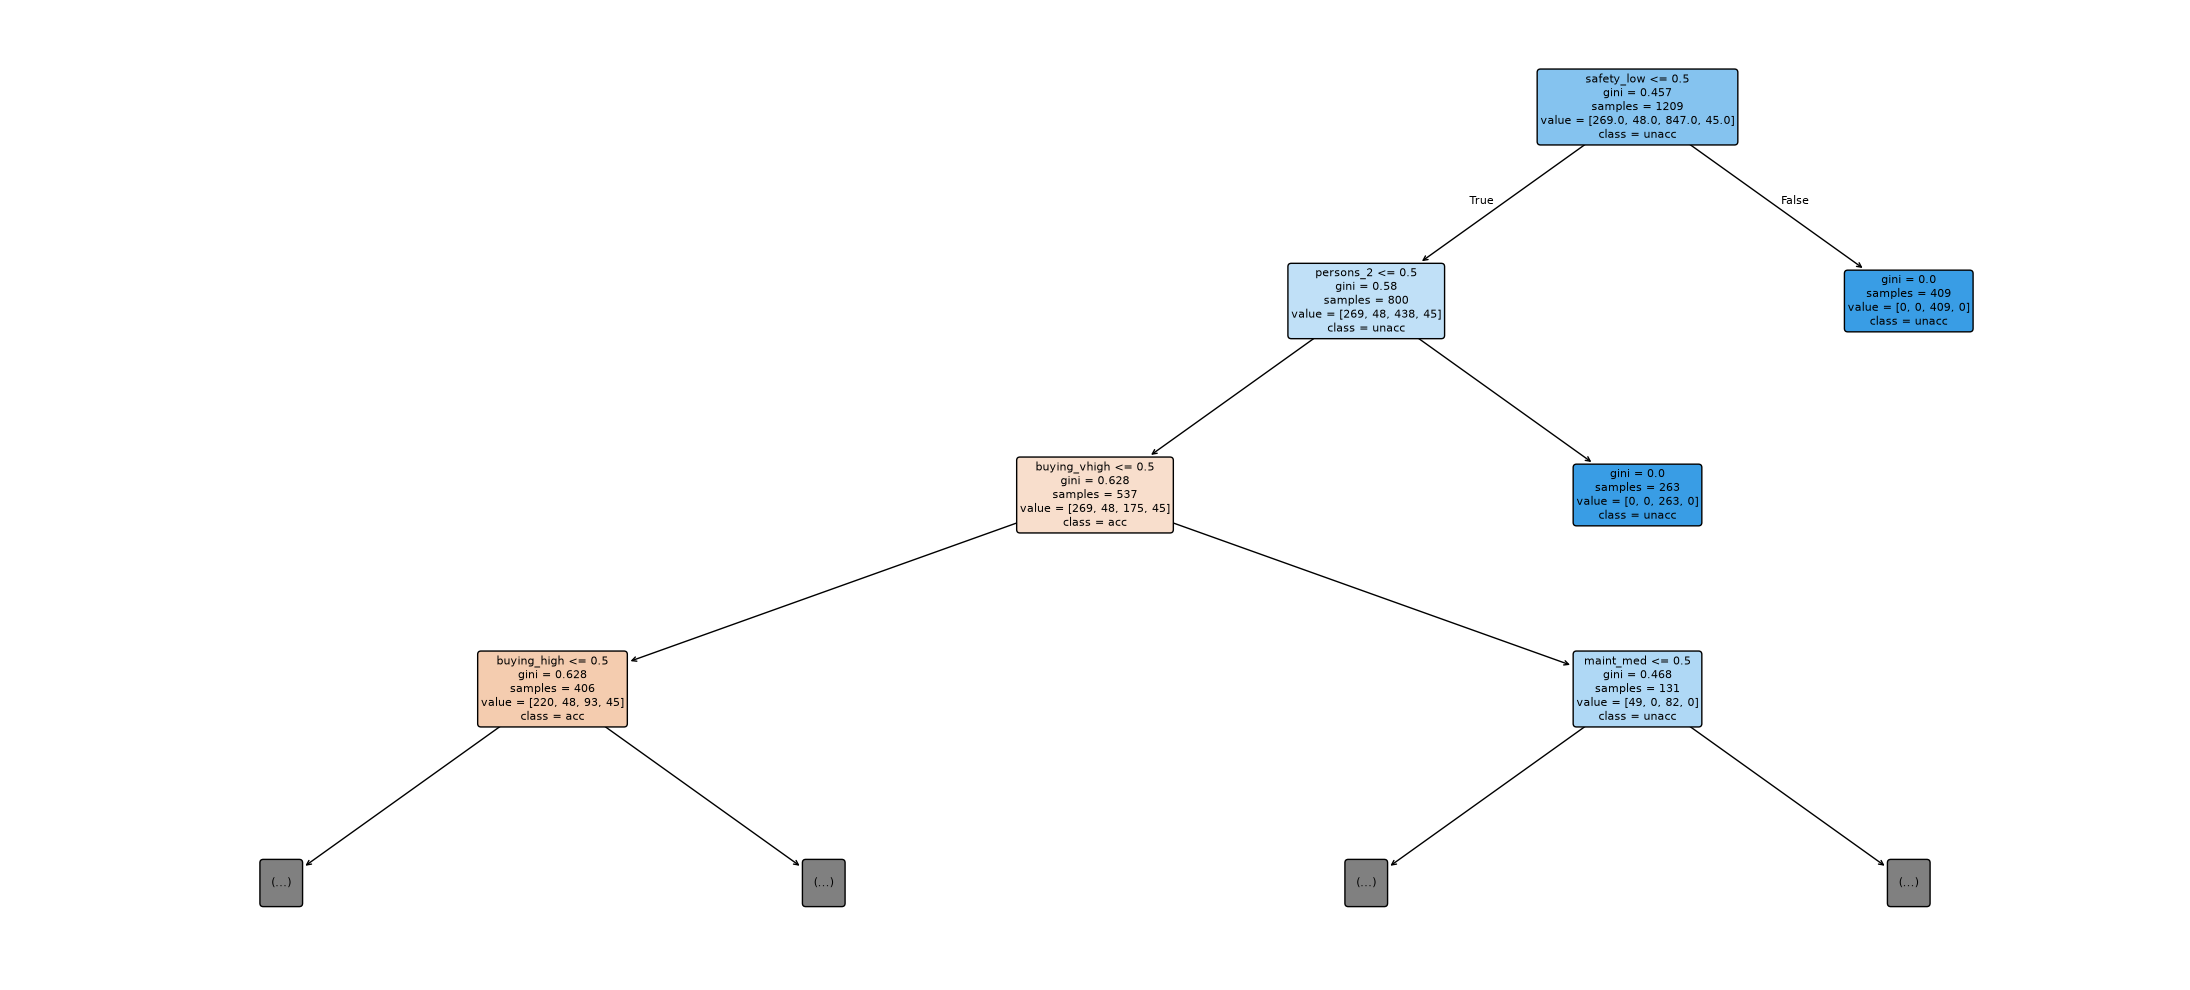

In [10]:
from sklearn.tree import plot_tree

# Compare shallow and deeper trees using the same stratified folds.
depth_candidates = [1, 2, 3, 5, 10, 15, 20, 30,None]
depth_results = []
for depth in depth_candidates:
    tree_pipeline = make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        DecisionTreeClassifier(max_depth=depth, random_state=1)
    )
    accuracy_scores = cross_val_score(
        tree_pipeline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1
    )
    macro_f1_scores = cross_val_score(
        tree_pipeline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1
    )
    depth_results.append({
        "max_depth": depth if depth is not None else "None",
        "Mean accuracy": accuracy_scores.mean(),
        "Mean macro F1": macro_f1_scores.mean(),
    })

depth_results_df = pd.DataFrame(depth_results)
display(depth_results_df)

# Select the depth with the best mean macro F1, then evaluate on the held-out test set.
best_depth_label = depth_results_df.loc[depth_results_df["Mean macro F1"].idxmax(), "max_depth"]
best_depth = None if best_depth_label == "None" else int(best_depth_label)
best_tree_pipeline = make_pipeline(
    OneHotEncoder(handle_unknown="ignore"),
    DecisionTreeClassifier(max_depth=best_depth, random_state=1)
)
best_tree_pipeline.fit(X_train, y_train)
print(f"Selected max_depth: {best_depth}")
print(f"Held-out test accuracy: {best_tree_pipeline.score(X_test, y_test):.3f}")

# Compare test accuracy with the linear models and the default-depth tree.
from sklearn.base import clone
comparison_models = {
    "Logistic Regression": logistic_regression,
    "SVM": svm,
    "Decision Tree (default depth)": decision_tree,
}
test_accuracy_comparison = []
for name, estimator in comparison_models.items():
    comparison_pipeline = make_pipeline(
        OneHotEncoder(handle_unknown="ignore"), clone(estimator)
    )
    comparison_pipeline.fit(X_train, y_train)
    test_accuracy_comparison.append({
        "Model": name,
        "Test accuracy": comparison_pipeline.score(X_test, y_test),
    })
test_accuracy_comparison.append({
    "Model": f"Decision Tree (max_depth={best_depth})",
    "Test accuracy": best_tree_pipeline.score(X_test, y_test),
})
pd.DataFrame(test_accuracy_comparison).sort_values("Test accuracy", ascending=False)

# Each probability column corresponds to one class in this order.
tree_estimator = best_tree_pipeline.named_steps["decisiontreeclassifier"]

# Visualize the selected tree; max_depth here limits only the displayed diagram.
encoded_feature_names = best_tree_pipeline.named_steps["onehotencoder"].get_feature_names_out()
plt.figure(figsize=(22, 10))
plot_tree(
    tree_estimator, max_depth=3, feature_names=encoded_feature_names,
    class_names=[str(label) for label in tree_estimator.classes_],
    filled=True, rounded=True, fontsize=8
)
plt.tight_layout()
plt.show()

## Compare chi-square feature selection

This compares each classifier using all six original features with using the three features that have the strongest chi-square association with the target. The chi-square statistic is calculated from a feature-by-class contingency table. Selection happens within each cross-validation fold to prevent data leakage.

In [15]:
from sklearn.base import BaseEstimator, TransformerMixin
from scipy.stats import chi2_contingency

class CategoricalChiSquareSelector(BaseEstimator, TransformerMixin):
    """Select original categorical columns by chi-square association with y."""
    def __init__(self, k=4):
        self.k = k

    def fit(self, X, y):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        y_values = np.asarray(y)
        self.scores_ = np.array([
            chi2_contingency(pd.crosstab(X.iloc[:, i], y_values), correction=False)[0]
            for i in range(X.shape[1])
        ])
        self.selected_indices_ = np.argsort(self.scores_)[::-1][:self.k]
        return self

    def transform(self, X):
        return X.iloc[:, self.selected_indices_]

# Compare all six original features with the top three, using the same stratified folds.
n_selected = 4
selection_results = []
for name, model in models.items():
    for setting in ["All 6 features", f"Top {n_selected} features by chi-square"]:
        steps = []
        if setting != "All 6 features":
            steps.append(CategoricalChiSquareSelector(k=n_selected))
        steps.extend([OneHotEncoder(handle_unknown="ignore"), model])
        pipeline = make_pipeline(*steps)

        accuracy_scores = cross_val_score(
            pipeline, X, y_1d, cv=cv, scoring="accuracy", n_jobs=-1
        )
        macro_f1_scores = cross_val_score(
            pipeline, X, y_1d, cv=cv, scoring="f1_macro", n_jobs=-1
        )
        selection_results.append({
            "Model": name,
            "Features": setting,
            "Mean accuracy": accuracy_scores.mean(),
            "Accuracy std": accuracy_scores.std(),
            "Mean macro F1": macro_f1_scores.mean(),
            "Macro F1 std": macro_f1_scores.std(),
        })

selection_results_df = pd.DataFrame(selection_results).sort_values(
    ["Model", "Features"]
)
selection_results_df

,Model,Features,Mean accuracy,Accuracy std,Mean macro F1,Macro F1 std
4,Decision Tree,All 6 features,0.978595,0.020465,0.937822,0.077581
5,Decision Tree,Top 4 features by chi-square,0.851824,0.022949,0.621360,0.093421
0,Logistic Regression,All 6 features,0.909737,0.024711,0.755505,0.085511
1,Logistic Regression,Top 4 features by chi-square,0.874445,0.027980,0.614218,0.093763
6,MLP,All 6 features,0.997681,0.004638,0.994921,0.012662
7,MLP,Top 4 features by chi-square,0.854163,0.026501,0.633647,0.095463
2,SVM,All 6 features,0.928254,0.019187,0.735914,0.089215
3,SVM,Top 4 features by chi-square,0.883688,0.025465,0.694423,0.084094


It performs worse when chi-square is applied.

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin
from scipy.stats import chi2_contingency

class CategoricalChiSquareSelector(BaseEstimator, TransformerMixin):
    """Select original categorical columns by chi-square association with y."""
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        y_values = np.asarray(y)
        self.scores_ = np.array([
            chi2_contingency(pd.crosstab(X.iloc[:, i], y_values), correction=False)[0]
            for i in range(X.shape[1])
        ])
        self.selected_indices_ = np.argsort(self.scores_)[::-1][:self.k]
        return self

    def transform(self, X):
        return X.iloc[:, self.selected_indices_]

# Compare all six original features with the top three, using the same stratified folds.
n_selected = 5
selection_results = []
for name, model in models.items():
    for setting in ["All 6 features", f"Top {n_selected} features by chi-square"]:
        steps = []
        if setting != "All 6 features":
            steps.append(CategoricalChiSquareSelector(k=n_selected))
        steps.extend([OneHotEncoder(handle_unknown="ignore"), model])
        pipeline = make_pipeline(*steps)

        accuracy_scores = cross_val_score(
            pipeline, X, y_1d, cv=cv, scoring="accuracy", n_jobs=-1
        )
        macro_f1_scores = cross_val_score(
            pipeline, X, y_1d, cv=cv, scoring="f1_macro", n_jobs=-1
        )
        selection_results.append({
            "Model": name,
            "Features": setting,
            "Mean accuracy": accuracy_scores.mean(),
            "Accuracy std": accuracy_scores.std(),
            "Mean macro F1": macro_f1_scores.mean(),
            "Macro F1 std": macro_f1_scores.std(),
        })

selection_results_df = pd.DataFrame(selection_results).sort_values(
    ["Model", "Features"]
)
selection_results_df

,Model,Features,Mean accuracy,Accuracy std,Mean macro F1,Macro F1 std
4,Decision Tree,All 6 features,0.978595,0.020465,0.937822,0.077581
5,Decision Tree,Top 5 features by chi-square,0.944440,0.024950,0.867052,0.070028
0,Logistic Regression,All 6 features,0.909737,0.024711,0.755505,0.085511
1,Logistic Regression,Top 5 features by chi-square,0.901617,0.036350,0.737004,0.082699
6,MLP,All 6 features,0.997681,0.004638,0.994921,0.012662
7,MLP,Top 5 features by chi-square,0.944453,0.028399,0.866840,0.072851
2,SVM,All 6 features,0.928254,0.019187,0.735914,0.089215
3,SVM,Top 5 features by chi-square,0.935759,0.027586,0.766636,0.086564


## Compare feature importance across all four models

Permutation importance measures how much test accuracy drops when one original input feature is shuffled. Larger drops indicate greater reliance on that feature. The encoder stays inside each pipeline, so the six categorical columns are assessed as whole features.

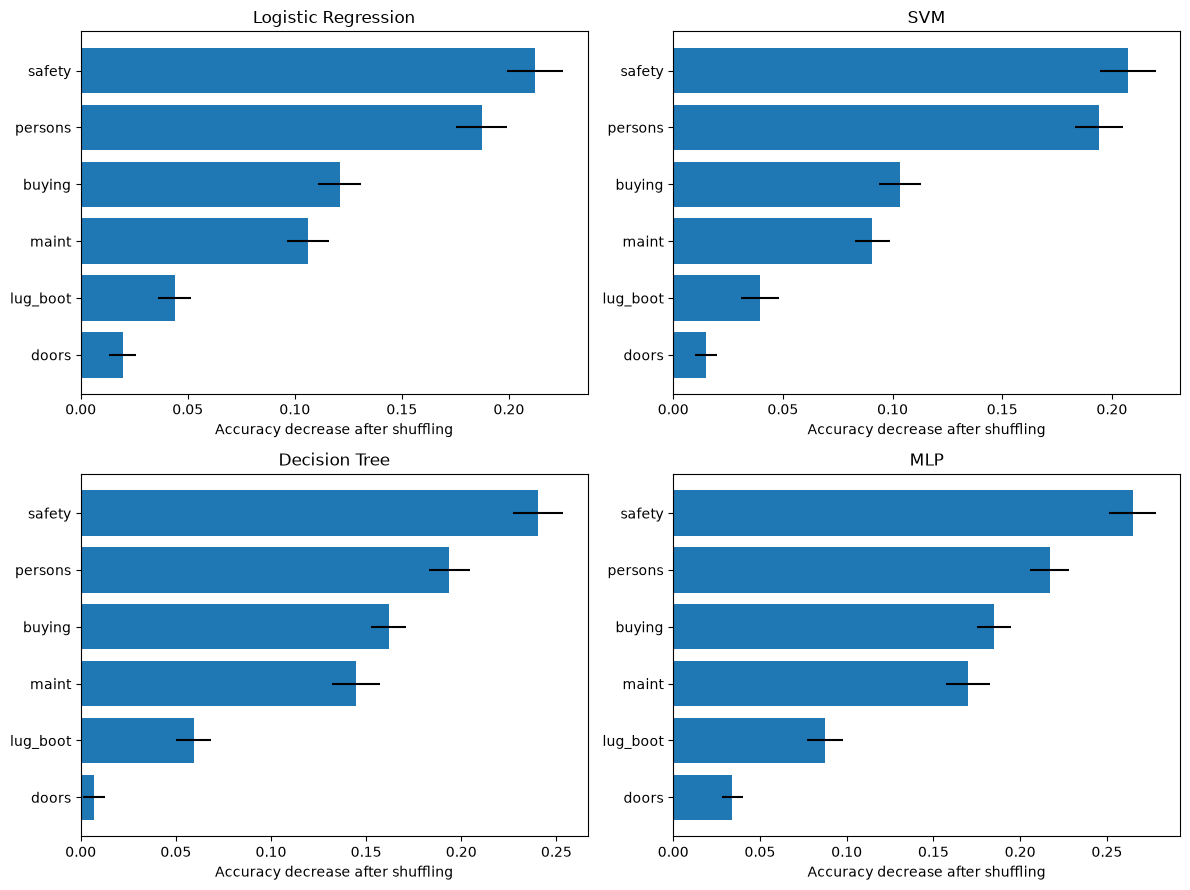

,Model,Feature,Mean accuracy decrease,Std. dev.
0,Logistic Regression,safety,0.212331,0.013110
1,Logistic Regression,persons,0.187219,0.011910
2,Logistic Regression,buying,0.121002,0.010140
3,Logistic Regression,maint,0.105973,0.009787
4,Logistic Regression,lug_boot,0.043866,0.007718
5,Logistic Regression,doors,0.019653,0.006379
6,SVM,safety,0.207193,0.012846
7,SVM,persons,0.194091,0.010853
8,SVM,buying,0.103468,0.009636
9,SVM,maint,0.090816,0.007925


In [12]:
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import matplotlib.pyplot as plt

models_for_importance = {
    "Logistic Regression": logistic_regression,
    "SVM": svm,
    "Decision Tree": decision_tree,
    "MLP": mlp,
}

all_importances = []
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, model) in zip(axes.flat, models_for_importance.items()):
    pipeline = make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        clone(model)
    )
    pipeline.fit(X_train, y_train)
    importance = permutation_importance(
        pipeline, X_test, y_test,
        scoring="accuracy", n_repeats=30, random_state=42, n_jobs=-1
    )

    model_importance = pd.DataFrame({
        "Model": name,
        "Feature": X.columns,
        "Mean accuracy decrease": importance.importances_mean,
        "Std. dev.": importance.importances_std,
    }).sort_values("Mean accuracy decrease", ascending=False)
    all_importances.append(model_importance)

    plot_data = model_importance.sort_values("Mean accuracy decrease")
    ax.barh(
        plot_data["Feature"], plot_data["Mean accuracy decrease"],
        xerr=plot_data["Std. dev."]
    )
    ax.set_title(name)
    ax.set_xlabel("Accuracy decrease after shuffling")

plt.tight_layout()
plt.show()

importance_df = pd.concat(all_importances, ignore_index=True)
importance_df